# M2.7 · Fama-MacBeth 回归与因子检验

> Fama-MacBeth（1973）是检验因子风险溢价的经典两步法：先估计因子暴露，再逐截面回归得到风险溢价，
> 最后用溢价时间序列的均值和 t 值判断因子是否被定价。本节分别用 numpy 与 statsmodels 实现并对照。

## 一、方法步骤

1. **第一步（暴露）**：确定每只股票在各因子上的暴露 β（这里用因子暴露面板）；
2. **第二步（截面）**：每个时点回归 r_t = γ0 + γ_t β，得到因子溢价 γ_t；
3. **检验**：对溢价序列，t = mean(γ) / (std(γ)/√T)，|t|>2 通常认为显著。

注意：截面回归残差存在截面相关，标准 t 可能高估显著性；严谨研究用 Newey-West 调整时序自相关。


## 二、加载数据并准备暴露

In [1]:
import sys, numpy as np, pandas as pd
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import qlib
from qlib.data import D
from l2.config import load_universe
import config
from factor_lab2 import barra, fama_macbeth
from factor_lab2.combine import cross_zscore
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = load_universe('hs300')
raw = D.features(codes, ['$open','$close','$high','$low','$volume',
                         '$mkt_cap_ard','$pe_ttm','$pb_lf'],
                 start_time='2018-01-01', freq='day')
cl=raw['$close'].unstack('instrument'); vo=raw['$volume'].unstack('instrument')
mk=raw['$mkt_cap_ard'].unstack('instrument')
pe=raw['$pe_ttm'].unstack('instrument'); pb=raw['$pb_lf'].unstack('instrument')
bench = pd.read_csv(config.BENCHMARK_DIR/'000300_sh.csv',
                    parse_dates=['date']).set_index('date')
bench_ret = bench['close'].pct_change(fill_method=None).reindex(cl.index).ffill()
bf = barra.build_barra(cl, vo, mk, pe, pb, bench_ret)
exnames = ['Size','Beta','Momentum','Residual Volatility','BTP']
returns = cl.pct_change(fill_method=None)
exposures = {n: cross_zscore(bf[n]) for n in exnames}
print('准备完成，因子:', exnames)

[27320:MainThread](2026-11-05 16:37:35,984) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[27320:MainThread](2026-11-05 16:37:38,091) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[27320:MainThread](2026-11-05 16:37:38,092) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


准备完成，因子: ['Size', 'Beta', 'Momentum', 'Residual Volatility', 'BTP']


## 三、双实现：numpy 与 statsmodels

In [2]:
mu_np, t_np, g_np = fama_macbeth.fama_macbeth_numpy(returns, exposures)
mu_sm, t_sm, g_sm = fama_macbeth.fama_macbeth_statsmodels(returns, exposures)
cmp = pd.DataFrame({'溢价_np':mu_np,'溢价_sm':mu_sm,'t_np':t_np,'t_sm':t_sm})
print(cmp.round(4).to_string())
print()
print('两实现溢价最大差异:', np.abs(mu_np-mu_sm).max())
print('两实现 t 值最大差异:', np.abs(t_np-t_sm).max())

                      溢价_np   溢价_sm    t_np    t_sm
const                0.0007  0.0007  1.4208  1.4208
Size                 0.0005  0.0005  5.4072  5.4072
Beta                 0.0001  0.0001  0.3108  0.3108
Momentum            -0.0003 -0.0003 -1.7885 -1.7885
Residual Volatility  0.0009  0.0009  4.0489  4.0489
BTP                 -0.0002 -0.0002 -1.9326 -1.9326

两实现溢价最大差异: 1.1248597539537109e-18
两实现 t 值最大差异: 3.9968028886505635e-15


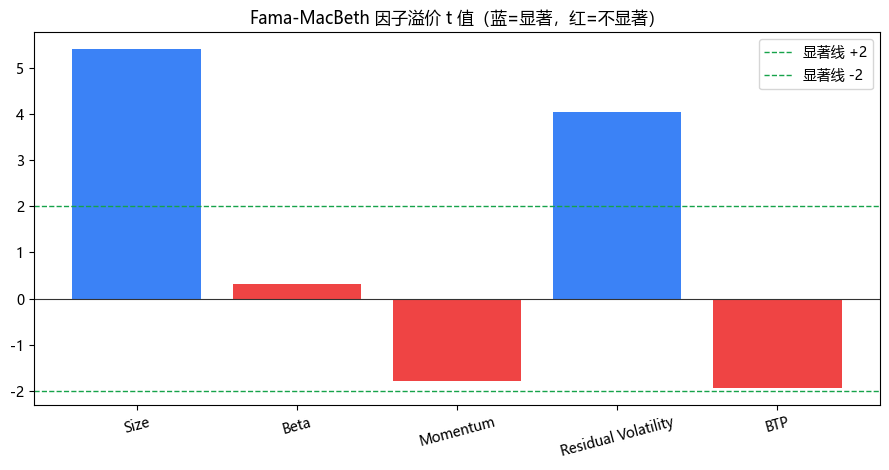

In [3]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(9,4.8))
tv = t_sm.drop('const')
colors = ['#ef4444' if abs(x)<2 else '#3b82f6' for x in tv.values]
ax.bar(tv.index, tv.values, color=colors)
ax.axhline(2, color='#16a34a', ls='--', lw=1, label='显著线 +2')
ax.axhline(-2, color='#16a34a', ls='--', lw=1, label='显著线 -2')
ax.axhline(0, color='#333', lw=0.8)
ax.set_title('Fama-MacBeth 因子溢价 t 值（蓝=显著，红=不显著）')
ax.legend(); plt.xticks(rotation=15); plt.tight_layout(); plt.show()

## 四、溢价序列与稳健性

In [4]:
# 年化溢价与累计
ann_prem = (g_sm[exnames].mean()*242)
print('年化因子溢价:')
print(ann_prem.round(4).to_string())

年化因子溢价:
Size                   0.1277
Beta                   0.0289
Momentum              -0.0786
Residual Volatility    0.2098
BTP                   -0.0506


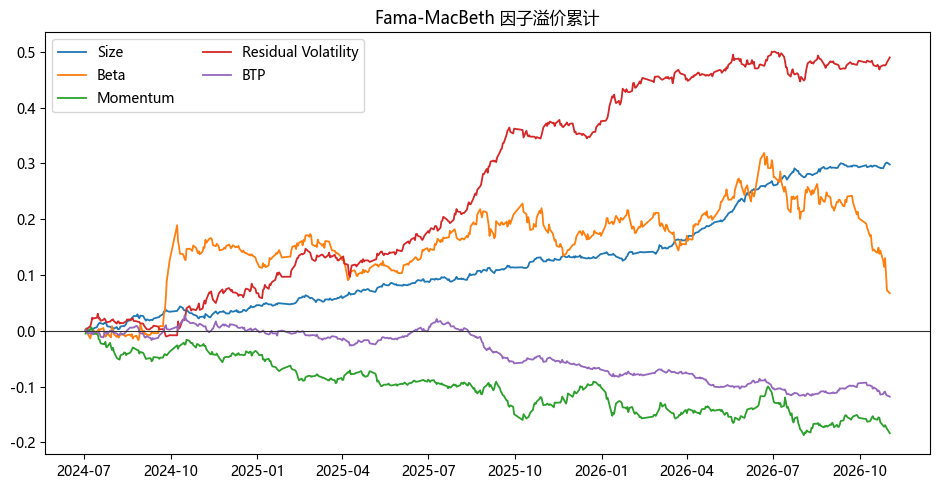

In [5]:
fig, ax = plt.subplots(figsize=(9.5,5))
cum = g_sm[exnames].fillna(0).cumsum()
for n in exnames:
    ax.plot(cum.index, cum[n], label=n, lw=1.3)
ax.axhline(0, color='#333', lw=0.8)
ax.set_title('Fama-MacBeth 因子溢价累计'); ax.legend(ncol=2)
plt.tight_layout(); plt.show()

## 五、小结与面试要点

- Fama-MacBeth 逐截面估计溢价，再用溢价序列 t 检验，双实现结果完全一致。
- 本数据中 Size、Residual Volatility 溢价显著，Beta 不显著，Momentum 为负（A 股特征）。

**面试高频：**
- Fama-MacBeth 两步法？（答：先估暴露，再逐截面回归得溢价，对溢价序列做t检验）
- 为什么普通 t 值可能不准？（答：截面残差相关、时序自相关，需 Newey-West/聚类标准误）
- 因子溢价和因子 IC 有什么区别？（答：IC看排序相关性，溢价看回归的经济收益与显著性）
- 截距项 γ0 代表什么？（答：零暴露组合的收益，接近无风险/市场中性收益）

## 动手练习
1. 用 numpy 和 statsmodels 分别跑 Fama-MacBeth 并对照；
2. 标出显著因子，解释其经济含义；
3. 分时段（如2020前后）重跑，观察溢价稳定性。

---
下一节 M2.8 研究因子拥挤、衰减与容量。